In [1]:
import numpy as np


In [2]:
def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def binary_cross_entropy(y_true, y_pred, eps=1e-12):
    y_pred = np.clip(y_pred, eps, 1 - eps)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

In [3]:
y_true = np.array([1, 0, 1, 1, 0, 0, 1, 0])
y_pred = np.array([0.9, 0.2, 0.8, 0.6, 0.3, 0.1, 0.7, 0.4])

In [4]:
mse_value = mean_squared_error(y_true, y_pred)       # not "mean_squared_error ="
bce_value = binary_cross_entropy(y_true, y_pred)     # not "binary_cross_entropy ="


In [5]:
print(f"MSE : {mse_value:.4f}")
print(f"BCE : {bce_value:.4f}")

print("\nConfidently wrong prediction (y=1, p=0.01):")
print(f"MSE : {mean_squared_error(1, 0.01):.4f}")
print(f"BCE : {binary_cross_entropy(1, 0.01):.4f}")

MSE : 0.0750
BCE : 0.2990

Confidently wrong prediction (y=1, p=0.01):
MSE : 0.9801
BCE : 4.6052


In [6]:
# ---------- Loss curves for true label = 1 ----------
p = np.linspace(0.001, 0.999, 500)
mse_curve = (1 - p) ** 2
bce_curve = -np.log(p)

In [7]:
import matplotlib.pyplot as plt

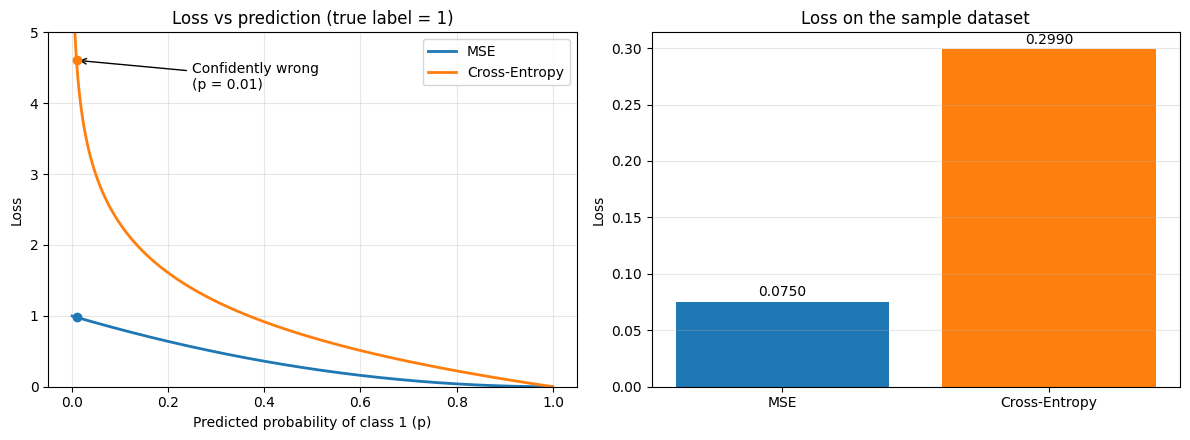

In [8]:
# ---------- Plot ----------
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Left: loss vs predicted probability
ax = axes[0]
ax.plot(p, mse_curve, label="MSE", linewidth=2)
ax.plot(p, bce_curve, label="Cross-Entropy", linewidth=2)
ax.scatter([0.01], [0.9801], color="C0", zorder=5)
ax.scatter([0.01], [4.6052], color="C1", zorder=5)
ax.annotate("Confidently wrong\n(p = 0.01)", xy=(0.01, 4.6052),
            xytext=(0.25, 4.2), arrowprops=dict(arrowstyle="->"))
ax.set_ylim(0, 5)
ax.set_xlabel("Predicted probability of class 1 (p)")
ax.set_ylabel("Loss")
ax.set_title("Loss vs prediction (true label = 1)")
ax.legend()
ax.grid(alpha=0.3)

# Right: loss values on the sample dataset
ax = axes[1]
values = [mse_value, bce_value]
bars = ax.bar(["MSE", "Cross-Entropy"], values, color=["C0", "C1"])
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.005, f"{v:.4f}", ha="center")
ax.set_ylabel("Loss")
ax.set_title("Loss on the sample dataset")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("loss_comparison.png", dpi=150)   # saves the image for your report
plt.show()